# HW2: Policy Gradiant
> - Full Name: **Yasamin Rajabi**
> - Student ID: **402111197**


## Objective

In this notebook, you will implement the **REINFORCE policy gradient algorithm** (also known as Monte Carlo policy gradient) to train an agent on the **CartPole‑v1** environment from OpenAI Gym. REINFORCE is a fundamental policy‑based reinforcement learning method that directly optimises the policy parameters by performing stochastic gradient ascent on the expected cumulative reward. However, the standard REINFORCE update is known to suffer from **high variance**, which can lead to slow convergence and unstable learning curves.

## Variance Reduction Techniques

To address this issue, this notebook further explores three variance‑reduction strategies that are commonly applied to the REINFORCE algorithm. You will implement each of them and empirically analyse their effects on learning speed, stability, and final performance. The techniques are:

1. **The causality trick (reward‑to‑go)**  
   Instead of using the full return from the start of an episode, this method replaces the cumulative reward with the sum of future rewards from each time step onward. By ignoring rewards obtained before the current action, the gradient estimator retains the same unbiasedness while significantly reducing variance.

2. **Constant baseline**  
   A fixed scalar baseline is subtracted from the return (or the reward‑to‑go) in the policy gradient estimate. Subtracting a constant does not introduce bias, but a well‑chosen constant (e.g., the average return over recent episodes) can reduce variance by centring the advantage estimates.

3. **Learned baseline (value function baseline)**  
   A more sophisticated approach that uses a separate function approximator (typically a neural network) to estimate the state‑value function. This learned baseline adapts during training and provides a state‑dependent offset. The advantage estimate then often yields the lowest variance among these three methods, at the cost of adding a second learning process.

## Implementation and Analysis

You will implement the core REINFORCE update, then systematically extend it with each of the three variance‑reduction techniques. For every variant, you will run multiple training episodes, plot the smoothed episode returns, and compare convergence behaviour. The notebook will guide you through:

- Setting up the CartPole‑v1 environment (discrete action space, continuous observation space).
- Defining a policy network (e.g., a shallow multi‑layer perceptron) with a softmax output layer.
- Writing the training loop that collects episodes, computes policy gradients, and updates the policy.
- Modifying the advantage estimator to incorporate causality and baseline subtractions.
- Training and evaluating each variant with identical random seeds for fair comparison.

By the end of this notebook, you will gain hands‑on insight into how different variance‑reduction mechanisms affect the practical performance of Monte Carlo policy gradient methods.

# Setup

All required packages are pre-installed if using Google Colab.


Import the following libraries.

In [23]:
# Imports
import numpy as np
if not hasattr(np, 'bool8'):
    np.bool8 = np.bool_

import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import gym
import matplotlib
import matplotlib.pyplot as plt
import base64
import imageio
import IPython
import logging
import warnings

# Disable warnings
logging.getLogger().setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=DeprecationWarning)

# DEVICE
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE

device(type='cpu')

Note: While we check for CUDA availability, using a GPU is not strictly necessary for this assignment. The neural networks used here are small, and the majority of training time is spent running episodes in the environment (which occurs on the CPU), rather than performing backpropagation updates.

Set a fix seed to be able to compare results

In [24]:
import random
def set_seed(seed=333):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(333)

Configure Matplotlib for Interactive and XKCD-Style Plots

In [25]:
# Set up matplotlib
is_ipython = 'inline' in matplotlib.get_backend()
if is_ipython:
    from IPython import display
plt.ion()
plt.xkcd(scale=1, length=100, randomness=2)
matplotlib.rcParams['figure.figsize'] = (12, 6)

Record and Embed Simulation Videos in Jupyter Notebook

<b>embed_mp4:</b> Converts an MP4 video into a base64-encoded HTML tag for display in Jupyter Notebook.
<br>
<b>record_simulation:</b> Runs a policy in the environment, records the simulation, and saves it as an MP4 video.

In [26]:
def embed_mp4(filename):
    video = open(filename,'rb').read()
    b64 = base64.b64encode(video)
    tag = '''
    <video width="640" height="480" controls>
    <source src="data:video/mp4;base64,{0}" type="video/mp4">
    Your browser does not support the video tag.
    </video>'''.format(b64.decode())
    return IPython.display.HTML(tag)

def record_simulation(env, policy_net, filename, episodes=1, fps=30):
    filename = filename + ".mp4"
    with imageio.get_writer(filename, fps=fps) as video:
        for _ in range(episodes):
            reset_output = env.reset()
            if isinstance(reset_output, tuple):
                state = reset_output[0]
            else:
                state = reset_output
                
            frame = env.render()  
            video.append_data(frame) 

            done = False
            while not done:
                state_tensor = torch.FloatTensor(state).to(DEVICE)
                action = torch.argmax(policy_net(state_tensor)).item()
                state, _, terminated, truncated, _ = env.step(action)

                frame = env.render()  
                video.append_data(frame) 

                done = terminated or truncated
    return embed_mp4(filename)

# Explore the environment

Initialize CartPole Environment and Display State & Action Spaces

In [27]:
# Create the CartPole environment
env = gym.make("CartPole-v1")

# Print observation and action space
print("Observation Space:", env.observation_space)
print("Action Space:", env.action_space)

Observation Space: Box([-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38], [4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38], (4,), float32)
Action Space: Discrete(2)


**Question**

How are the observation and action spaces defined in the CartPole environment?

**Answer:**

observation space => four dimensions: cart position, cart velocity, pole angle, and pole angular velocity. all of them are continuous. 
action space => Discrete(2), push the cart left or push it right


Define a Random Policy for Action Selection  

In [28]:
class RandomPolicy(object):

    def __init__(self, action_space_n):
        self.action_space_n = action_space_n

    def __call__(self, state):
        action_values = torch.rand(self.action_space_n)
        return action_values

Visualize the random policy.

In [29]:
import numpy as np

random_policy = RandomPolicy(env.action_space.n)
max_step_per_episode = 10000
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), random_policy, "Video_CartPole_random_policy")

# Agent with REINFORCE: Normal vs Causality vs Simple Baseline vs Learned Baseline


### Policy Network Definition

To define a neural network that represents the agent’s policy for selecting actions.

The policy network takes the environment’s state as input and outputs a probability distribution over possible actions.

In [30]:
# TODO: Define the Policy Network
class PolicyNetwork(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(PolicyNetwork, self).__init__()
        self.policy_net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, output_dim)
        )
        # Implement a simple MLP policy
        pass

    def forward(self, state):
        # Return a probability distribution over actions
        return torch.softmax(self.policy_net(state), dim=-1)

### REINFORCE without Causality

#### 1. The Objective Function
In Policy Gradient methods, we aim to maximize the expected return:
$$J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta} [G(\tau)]$$
where $\tau = (s_0, a_0, s_1, a_1, \dots, s_T)$ is a trajectory sampled from the policy $\pi_\theta$, and $G(\tau)$ is the total discounted return.

#### 2. The Policy Gradient Theorem
The gradient of the objective function is given by:
$$\nabla_\theta J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta} \left[ \left( \sum_{t=0}^{T} \nabla_\theta \log \pi_\theta(a_t | s_t) \right) G(\tau) \right]$$

#### 3. Full Return vs. Reward-to-go
In the code implementation `reinforce_no_causality`, we use the **Full Return** $G_0$ for every action in the trajectory:
- **Definition of $G_0$**: $G_0 = \sum_{k=0}^{T} \gamma^k R_k$
- **Update Rule**: $\theta \leftarrow \theta + \alpha \sum_{t=0}^{T} \nabla_\theta \log \pi_\theta(a_t | s_t) G_0$

#### Definitions:
- **$\pi_\theta(a_t | s_t)$**: The probability of taking action $a_t$ given state $s_t$ under parameters $\theta$.
- **$\nabla_\theta \log \pi_\theta(a_t | s_t)$**: The 'score function' or direction in parameter space that increases the probability of action $a_t$.
- **$G_0$**: The total scalar reward of the entire episode. If the episode was good, $G_0$ is high, and we push the probabilities of *all* actions taken in that episode 'up' equally.


In [39]:
# TODO: Implement REINFORCE without causality (using Full Return G_0)
def reinforce_no_causality(env, policy_net, optimizer, num_episodes=1000, gamma=0.99):
    rewards_per_episode = []

    for episode in range(num_episodes):
        G = 0.0
        sum_rewards = 0
        log_probs = []

        ob, _ = env.reset() if isinstance(env.reset(), tuple) else (env.reset(), None)
        state = ob if isinstance(ob, tuple) else ob

        done = False
        for step in range(max_step_per_episode):
            if(done):
                break
            
            state = torch.FloatTensor(state if not isinstance(state, tuple) else state[0]).to(DEVICE)
            action_probs = policy_net(state)
            categorical = Categorical(action_probs)
            action  = categorical.sample()
            lp = categorical.log_prob(action)

            out = env.step(action.item())
            if len(out) == 4:
                state, reward, done, _ = out
            else:
                state, reward, terminated, truncated, _ = out
                done = terminated or truncated

            log_probs.append(lp)
            G = G + (gamma ** step) * reward
            sum_rewards += reward
        
        loss = torch.stack([-lp * G for lp in log_probs]).sum()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rewards_per_episode.append(sum_rewards)
        if (episode + 1) % 50 == 0:
            print(f"[Simple] Episode {episode + 1}, Reward: {sum_rewards}")


        pass
    return rewards_per_episode

**Question:**

Why does this method has high variance?



**Answer:**

The value of the loss is equal to the average of the sum of the policy logarithm gradient multiplied by the sum of rewards obtained for different trajectories.  
The sum of the rewards has very high variance because different scenarios can lead to very different rewards, especially in environments with sparse reward distributions.

### REINFORCE with Causality

To implement a function that calculates the discounted return for each timestep in an episode.

$$[
G_t = \sum_{k=0}^{T-t} \gamma^k R_{t+k}
]$$

In [40]:
# TODO: Implement the function to compute discounted returns (Reward-to-go)
def compute_returns(rewards, gamma=0.99):
    discounted = []
    cum = 0
    for r in rewards[::-1]:
        cum = r + gamma * cum
        discounted.append(cum)
    return discounted[::-1]

To train the agent using the standard policy gradient method.
The REINFORCE algorithm updates policy parameters by using the log-probability of actions multiplied by the discounted return.

This algorithm optimizes a **stochastic policy** $( \pi_{\theta}(a_t \mid s_t) )$ by updating its parameters in the direction that increases expected rewards. The update rule is based on the **policy gradient theorem**:  

$$[
\theta \leftarrow \theta + \alpha \sum_{t=0}^{T} \nabla_{\theta} \log \pi_{\theta}(a_t \mid s_t) G_t
]$$

where:  

- $( \theta )$ are the policy parameters (weights of the neural network).  
- $( \alpha )$ is the learning rate.  
- $( G_t )$ is the **discounted return** from timestep $( t )$:  

- $( \nabla_{\theta} \log \pi_{\theta}(a_t \mid s_t) )$ is the gradient of the log-probability of the selected action, used to adjust the policy in the correct direction.

In [42]:
# TODO: Implement the REINFORCE algorithm (with Causality, No Baseline)
def reinforce(env, policy_net, optimizer, num_episodes=1000, gamma=0.99):
    episode_rewards = []
    for ep in range(num_episodes):
        log_probs = []
        rewards = []

        reset = env.reset()
        state = reset[0] if isinstance(reset, tuple) else reset

        done = False
        for t in range(max_step_per_episode):
            if done:
                break

            state_t = torch.FloatTensor(state).to(DEVICE)
            probs = policy_net(state_t)
            dist = Categorical(probs)
            action = dist.sample()
            log_p = dist.log_prob(action)

            step = env.step(action.item())
            if len(step) == 4:
                state, reward, done, _ = step
            else:
                state, reward, terminated, truncated, _ = step
                done = terminated or truncated

            log_probs.append(log_p)
            rewards.append(reward)

        rets = compute_returns(rewards, gamma)
        rets = torch.FloatTensor(rets).to(DEVICE)

        loss = torch.stack([-lp * gt for lp, gt in zip(log_probs, rets)]).sum()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        episode_rewards.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"[Causality] Episode {ep + 1}, Reward: {sum(rewards)}")

    return episode_rewards

### REINFORCE with a Constant Baseline

A simple way to reduce variance is to subtract a constant baseline from the returns. A common choice for this constant is the average return of the episode:

$$\theta \leftarrow \theta + \alpha \sum_{t=0}^{T} \nabla_{\theta} \log \pi_{\theta}(a_t | s_t) (G_t - b)$$

where $b = \frac{1}{T} \sum_{t=0}^T G_t$.

In [44]:
# TODO: Implement REINFORCE with a Constant Baseline
def reinforce_constant_baseline(env, policy_net, optimizer, num_episodes=1000, gamma=0.99):
    all_rewards = []
    for ep in range(num_episodes):
        log_probs = []
        rewards = []

        reset = env.reset()
        state = reset[0] if isinstance(reset, tuple) else reset

        done = False
        for t in range(max_step_per_episode):
            if done:
                break

            state_t = torch.FloatTensor(state).to(DEVICE)
            action_probs = policy_net(state_t)
            dist = Categorical(action_probs)
            action = dist.sample()
            log_p = dist.log_prob(action)

            step = env.step(action.item())
            if len(step) == 4:
                state, reward, done, _ = step
            else:
                state, reward, terminated, truncated, _ = step
                done = terminated or truncated

            log_probs.append(log_p)
            rewards.append(reward)

        rets = compute_returns(rewards, gamma)
        rets_t = torch.FloatTensor(rets).to(DEVICE)

        baseline = rets_t.mean()
        advantages = rets_t - baseline

        loss = torch.stack([-lp * adv for lp, adv in zip(log_probs, advantages)]).sum()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        all_rewards.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"[Simple Baseline] Episode {ep + 1}, Reward: {sum(rewards)}")

    return all_rewards

### Value Network Definition (Baseline Network)

Defines a neural network that approximates the value function, which estimates the expected return from a given state. The network takes the environment’s state as input and outputs a scalar value, representing the long-term reward the agent can expect from that state.

In [35]:
# TODO: Define the Value Network (Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.bas_net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, state):
        return self.bas_net(state)

### Implementing REINFORCE with a Learned Baseline

To reduce variance in policy updates, we introduce a **baseline** function $( V(s) )$, which estimates the expected return from a given state. Instead of using the full return $( G_t )$, we adjust the policy update by incorporating the baseline:  

$$[
\theta \leftarrow \theta + \alpha \sum_{t=0}^{T} \nabla_{\theta} \log \pi_{\theta}(a_t \mid s_t) (G_t - V(s_t))
]$$

where:  

- $( \theta )$ are the policy parameters (weights of the neural network).  
- $( \alpha )$ is the learning rate.  
- $( G_t )$ is the **discounted return** from timestep $( t )$:  

  $$[
  G_t = \sum_{k=0}^{T-t} \gamma^k R_{t+k}
  ]$$

- $( V(s_t) )$ is the **baseline function**, estimated by a **value network**, which is trained using mean squared error (MSE) between predicted values and actual returns:  

  $$[
  L = \frac{1}{N} \sum_{t=0}^{N} (G_t - V(s_t))^2
  ]$$

The introduction of the baseline does not change the expected value of the gradient but significantly **reduces variance**, leading to more stable learning.  


In [45]:
# TODO: Implement REINFORCE with a Learned Baseline
def reinforce_with_baseline(env, policy_net, baseline_net, policy_optimizer, baseline_optimizer, num_episodes=1000, gamma=0.99):
    all_ep_rewards = []
    for ep in range(num_episodes):
        states = []
        log_probs = []
        rewards = []

        reset = env.reset()
        state = reset[0] if isinstance(reset, tuple) else reset

        done = False
        for t in range(max_step_per_episode):
            if done:
                break

            state_t = torch.FloatTensor(state).to(DEVICE)
            act_probs = policy_net(state_t)
            dist = Categorical(act_probs)
            action = dist.sample()
            log_p = dist.log_prob(action)

            step = env.step(action.item())
            if len(step) == 4:
                state, reward, done, _ = step
            else:
                state, reward, terminated, truncated, _ = step
                done = terminated or truncated

            states.append(state_t)
            log_probs.append(log_p)
            rewards.append(reward)

        rets = compute_returns(rewards, gamma)
        rets_t = torch.FloatTensor(rets).to(DEVICE)

        values = torch.cat([baseline_net(s) for s in states])

        advantages = rets_t - values.detach()
        policy_loss = torch.stack([-lp * adv for lp, adv in zip(log_probs, advantages)]).sum()

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        v_loss = nn.MSELoss()(values, rets_t)
        baseline_optimizer.zero_grad()
        v_loss.backward()
        baseline_optimizer.step()

        all_ep_rewards.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"[Learned Baseline] Episode {ep + 1}, Reward: {sum(rewards)}")

    return all_ep_rewards

### Training

To define key hyperparameters that influence training efficiency and convergence.

Hyperparameters like learning rate, discount factor, and number of episodes significantly impact the training process. Proper tuning is necessary to ensure stable learning while avoiding slow convergence or premature convergence to suboptimal policies.

In [50]:
# TODO: Defines all necessary hyperparameters
INPUT_DIM = 4
OUTPUT_DIM = 2
LEARNING_RATE = 8e-4
DISCOUNT_FACTOR = 0.99
NUM_EPISODES = 2000

In [51]:
# 1. Training REINFORCE without Causality (Full Return)
print("--- Training REINFORCE: No Causality (Full Return) ---")
# Use a fresh policy network
policy_net_no_causality = PolicyNetwork(INPUT_DIM, OUTPUT_DIM).to(DEVICE)
optimizer_no_causality = optim.Adam(policy_net_no_causality.parameters(), lr=LEARNING_RATE)

rewards_no_causality = reinforce_no_causality(
    env, policy_net_no_causality, optimizer_no_causality,
    num_episodes=NUM_EPISODES, gamma=DISCOUNT_FACTOR
)

--- Training REINFORCE: No Causality (Full Return) ---
[Simple] Episode 50, Reward: 10.0
[Simple] Episode 100, Reward: 20.0
[Simple] Episode 150, Reward: 78.0
[Simple] Episode 200, Reward: 38.0
[Simple] Episode 250, Reward: 21.0
[Simple] Episode 300, Reward: 34.0
[Simple] Episode 350, Reward: 44.0
[Simple] Episode 400, Reward: 43.0
[Simple] Episode 450, Reward: 36.0
[Simple] Episode 500, Reward: 51.0
[Simple] Episode 550, Reward: 91.0
[Simple] Episode 600, Reward: 53.0
[Simple] Episode 650, Reward: 47.0
[Simple] Episode 700, Reward: 65.0
[Simple] Episode 750, Reward: 55.0
[Simple] Episode 800, Reward: 22.0
[Simple] Episode 850, Reward: 59.0
[Simple] Episode 900, Reward: 89.0
[Simple] Episode 950, Reward: 143.0
[Simple] Episode 1000, Reward: 77.0
[Simple] Episode 1050, Reward: 121.0
[Simple] Episode 1100, Reward: 49.0
[Simple] Episode 1150, Reward: 54.0
[Simple] Episode 1200, Reward: 144.0
[Simple] Episode 1250, Reward: 81.0
[Simple] Episode 1300, Reward: 152.0
[Simple] Episode 1350, Re

In [52]:
# 2. Training REINFORCE with Causality (No Baseline)
print("--- Training REINFORCE: With Causality (No Baseline) ---")
policy_net_causality = PolicyNetwork(INPUT_DIM, OUTPUT_DIM).to(DEVICE)
optimizer_causality = optim.Adam(policy_net_causality.parameters(), lr=LEARNING_RATE)

rewards_no_baseline = reinforce(
    env, policy_net_causality, optimizer_causality,
    num_episodes=NUM_EPISODES, gamma=DISCOUNT_FACTOR
)

--- Training REINFORCE: With Causality (No Baseline) ---
[Causality] Episode 50, Reward: 20.0
[Causality] Episode 100, Reward: 47.0
[Causality] Episode 150, Reward: 80.0
[Causality] Episode 200, Reward: 44.0
[Causality] Episode 250, Reward: 184.0
[Causality] Episode 300, Reward: 38.0
[Causality] Episode 350, Reward: 367.0
[Causality] Episode 400, Reward: 297.0
[Causality] Episode 450, Reward: 330.0
[Causality] Episode 500, Reward: 149.0
[Causality] Episode 550, Reward: 282.0
[Causality] Episode 600, Reward: 500.0
[Causality] Episode 650, Reward: 500.0
[Causality] Episode 700, Reward: 454.0
[Causality] Episode 750, Reward: 500.0
[Causality] Episode 800, Reward: 500.0
[Causality] Episode 850, Reward: 500.0
[Causality] Episode 900, Reward: 500.0
[Causality] Episode 950, Reward: 500.0
[Causality] Episode 1000, Reward: 500.0
[Causality] Episode 1050, Reward: 500.0
[Causality] Episode 1100, Reward: 500.0
[Causality] Episode 1150, Reward: 459.0
[Causality] Episode 1200, Reward: 442.0
[Causali

In [53]:
# 3. Training REINFORCE with Constant Baseline
print("--- Training REINFORCE: Constant Baseline ---")
policy_net_const_baseline = PolicyNetwork(INPUT_DIM, OUTPUT_DIM).to(DEVICE)
optimizer_const_baseline = optim.Adam(policy_net_const_baseline.parameters(), lr=LEARNING_RATE)

rewards_constant_baseline = reinforce_constant_baseline(
    env, policy_net_const_baseline, optimizer_const_baseline,
    num_episodes=NUM_EPISODES, gamma=DISCOUNT_FACTOR
)

--- Training REINFORCE: Constant Baseline ---
[Simple Baseline] Episode 50, Reward: 16.0
[Simple Baseline] Episode 100, Reward: 89.0
[Simple Baseline] Episode 150, Reward: 29.0
[Simple Baseline] Episode 200, Reward: 99.0
[Simple Baseline] Episode 250, Reward: 107.0
[Simple Baseline] Episode 300, Reward: 166.0
[Simple Baseline] Episode 350, Reward: 287.0
[Simple Baseline] Episode 400, Reward: 409.0
[Simple Baseline] Episode 450, Reward: 384.0
[Simple Baseline] Episode 500, Reward: 200.0
[Simple Baseline] Episode 550, Reward: 203.0
[Simple Baseline] Episode 600, Reward: 500.0
[Simple Baseline] Episode 650, Reward: 500.0
[Simple Baseline] Episode 700, Reward: 500.0
[Simple Baseline] Episode 750, Reward: 500.0
[Simple Baseline] Episode 800, Reward: 500.0
[Simple Baseline] Episode 850, Reward: 383.0
[Simple Baseline] Episode 900, Reward: 267.0
[Simple Baseline] Episode 950, Reward: 500.0
[Simple Baseline] Episode 1000, Reward: 146.0
[Simple Baseline] Episode 1050, Reward: 500.0
[Simple Base

In [54]:
# 4. Training REINFORCE with Learned Baseline
print("--- Training REINFORCE: Learned Baseline ---")
policy_net_learned_baseline = PolicyNetwork(INPUT_DIM, OUTPUT_DIM).to(DEVICE)
value_net_baseline = ValueNetwork(INPUT_DIM).to(DEVICE)

policy_opt_learned = optim.Adam(policy_net_learned_baseline.parameters(), lr=LEARNING_RATE)
value_opt_learned = optim.Adam(value_net_baseline.parameters(), lr=LEARNING_RATE)

rewards_with_baseline = reinforce_with_baseline(
    env, policy_net_learned_baseline, value_net_baseline,
    policy_opt_learned, value_opt_learned,
    num_episodes=NUM_EPISODES, gamma=DISCOUNT_FACTOR
)

--- Training REINFORCE: Learned Baseline ---
[Learned Baseline] Episode 50, Reward: 30.0
[Learned Baseline] Episode 100, Reward: 41.0
[Learned Baseline] Episode 150, Reward: 40.0
[Learned Baseline] Episode 200, Reward: 83.0
[Learned Baseline] Episode 250, Reward: 33.0
[Learned Baseline] Episode 300, Reward: 190.0
[Learned Baseline] Episode 350, Reward: 139.0
[Learned Baseline] Episode 400, Reward: 221.0
[Learned Baseline] Episode 450, Reward: 139.0
[Learned Baseline] Episode 500, Reward: 391.0
[Learned Baseline] Episode 550, Reward: 256.0
[Learned Baseline] Episode 600, Reward: 500.0
[Learned Baseline] Episode 650, Reward: 500.0
[Learned Baseline] Episode 700, Reward: 486.0
[Learned Baseline] Episode 750, Reward: 500.0
[Learned Baseline] Episode 800, Reward: 488.0
[Learned Baseline] Episode 850, Reward: 500.0
[Learned Baseline] Episode 900, Reward: 500.0
[Learned Baseline] Episode 950, Reward: 500.0
[Learned Baseline] Episode 1000, Reward: 500.0
[Learned Baseline] Episode 1050, Reward:

# Plot and Comparing Results


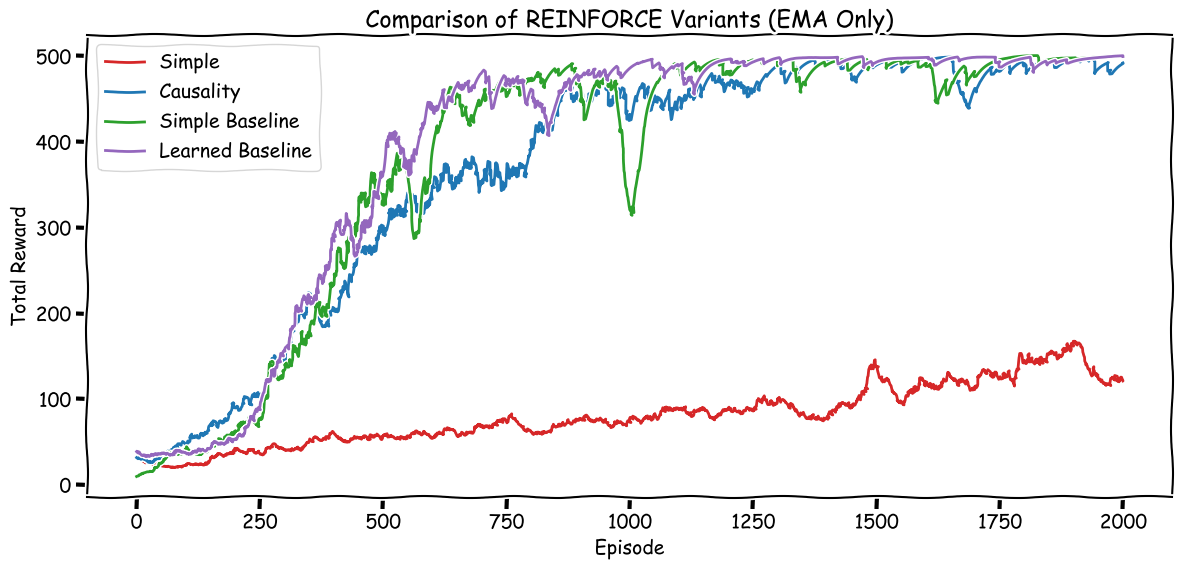

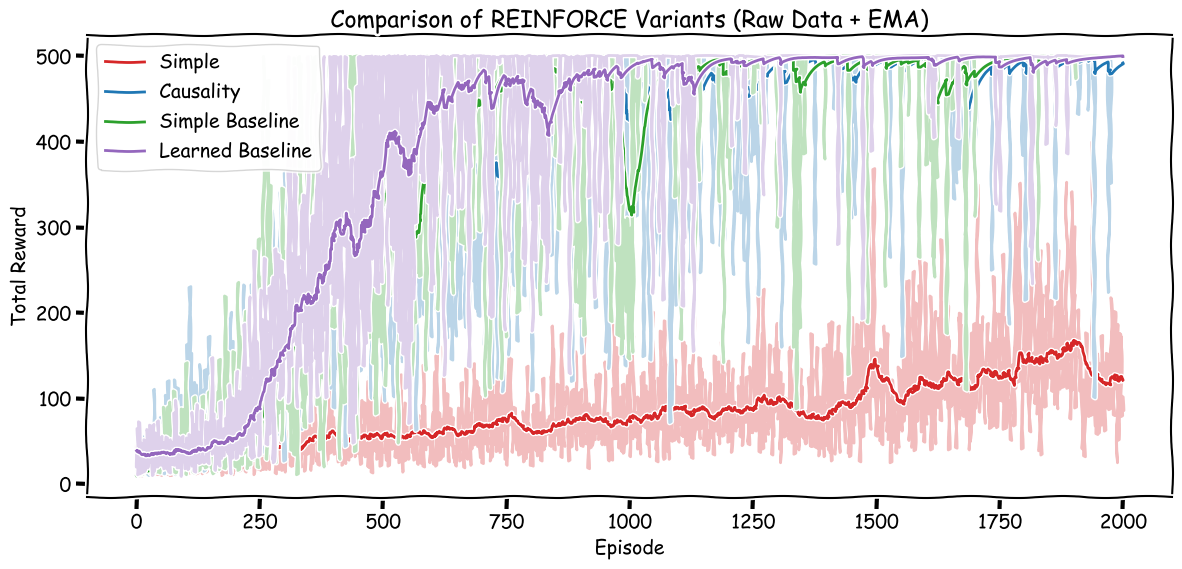

In [57]:
# TODO: Plotting Results
window_size = 50

def exponential_moving_average(data, window_size):
    alpha = 2.0 / (window_size + 1.0)
    result = [data[0]]
    for val in data[1:]:
        result.append(alpha * val + (1.0 - alpha) * result[-1])
    return result

# TODO: Plot the results for all 4 methods (Raw data + EMA)
# Use the 'methods' list below for consistent colors and labels
methods = [
    (rewards_no_causality, "Simple", "tab:red"),
    (rewards_no_baseline, "Causality", "tab:blue"),
    (rewards_constant_baseline, "Simple Baseline", "tab:green"),
    (rewards_with_baseline, "Learned Baseline", "tab:purple")
]

plt.figure(figsize=(14, 6))
for data, label, color in methods:
    plt.plot(exponential_moving_average(data, window_size), label=label, color=color, linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Comparison of REINFORCE Variants (EMA Only)")
plt.legend()
plt.show()

plt.figure(figsize=(14, 6))
for data, label, color in methods:
    plt.plot(data, alpha=0.3, color=color)
    plt.plot(exponential_moving_average(data, window_size), label=label, color=color, linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Comparison of REINFORCE Variants (Raw Data + EMA)")
plt.legend()
plt.show()

In [70]:
# Calculate and print statistics for all 4 methods
results_stats = [
    ("No Causality", rewards_no_causality),
    ("No Baseline", rewards_no_baseline),
    ("Constant Baseline", rewards_constant_baseline),
    ("Learned Baseline", rewards_with_baseline)
]

for name, rewards in results_stats:
    mean_reward = np.mean(rewards)
    std_reward = np.std(rewards)
    print(f"{name}: mean_reward = {mean_reward:.1f} +/- {std_reward:.1f}")

No Causality: mean_reward = 130.5 +/- 107.2
No Baseline: mean_reward = 356.5 +/- 173.5
Constant Baseline: mean_reward = 400.3 +/- 162.1
Learned Baseline: mean_reward = 399.9 +/- 167.0


**Question:**

Based on the results, how does REINFORCE with a baseline compare to REINFORCE without a baseline in terms of performance?

**Answer:**

When we use a baseline, we observe that the policy converges to the maximum reward much faster. The other two methods converge very slowly, and even when they converge, they exhibit high variance.


**Question:**

Based on the results, how does REINFORCE with a constant baseline compare to REINFORCE with a learned baseline in terms of performance?

**Answer:**

When using a learned baseline, we see a noticeable improvement in the above plots compared to when using a constant baseline. We also observe that with the constant baseline method, even at convergence, there is still variance and noise in the plot. However, in the learned baseline case, this noise approaches zero, and overall, it has slightly better variance.


**Question:**

Based on the results, how does REINFORCE without causality trick compare to REINFORCE with causality trick in terms of performance?


**Answer:**

When using causality, even without a baseline, the results significantly outperform others. The convergence speed is much higher, and the average total reward per episode increases dramatically. However, the problem of high variance is still noticeably present and has not been well resolved.

**Question:**

Explain how variance affects policy gradient methods, particularly in the context of estimating gradients from sampled trajectories.

**Answer:**

When the variance is high, we observe that over time steps, the average reward converges to the maximum reward, but this happens in a very noisy manner. Because when the variance in the gradient is high, even if we have reached the optimal policy, a noisy update can cause us to return to sub-optimal states, as can be seen in the plots. Then we have to try again to optimize the policy. This lack of consistency significantly harms our evaluation

# Simulation

In [62]:
# Record the simulation using the optimal policy no baseline
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), policy_net_causality, "Video_CartPole_no_baseline")

In [63]:
# Record the simulation using the policy trained without causality trick
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), policy_net_no_causality, "Video_CartPole_no_causality")

In [64]:
# Record the simulation using the policy trained with constant baseline
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), policy_net_const_baseline, "Video_CartPole_constant_baseline")

In [65]:
# Record the simulation using the optimal policy with baseline
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), policy_net_learned_baseline, "Video_CartPole_with_baseline")

**Question:**

According to the simulations, how does each algorithm perform on the task after the training?

**Answer:**

Based on both the videos and the plots, it can be said that except for the method that did not use causality, all other methods have successfully accomplished the task. That is, they have managed to keep the pole upright over the course of 500 time steps. This demonstrates the importance of the causality technique, both for reducing variance and for achieving the desired reward in the REINFORCE algorithm.